In [1]:
  !pip install missingno

# TP DataViz : NYC Taxi Trips
**Nom :** YARA YASSINE — **Classe :** BDML2 — **Année :** 2026

## 1. Chargement des données

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
import plotly.express as px

In [9]:
path2 = "https://raw.githubusercontent.com/uber-web/kepler.gl-data/master/nyctrips/data.csv"
df2 = pd.read_csv(path2, delimiter=',')
print(df2.shape)
df2.head()

(97986, 12)


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,fare_amount,tip_amount,total_amount
0,2,2015-01-15 19:05:39 +00:00,2015-01-15 19:23:42 +00:00,1,1.59,-73.993896,40.750111,-73.974785,40.750618,12.0,3.25,17.05
1,2,2015-01-15 19:05:39 +00:00,2015-01-15 19:32:00 +00:00,1,2.38,-73.976425,40.739811,-73.983978,40.757889,16.5,4.38,22.68
2,2,2015-01-15 19:05:40 +00:00,2015-01-15 19:21:00 +00:00,5,2.83,-73.968704,40.754246,-73.955124,40.786858,12.5,0.00,14.30
3,2,2015-01-15 19:05:40 +00:00,2015-01-15 19:28:18 +00:00,5,8.33,-73.863060,40.769581,-73.952713,40.785782,26.0,8.08,41.21
4,2,2015-01-15 19:05:41 +00:00,2015-01-15 19:20:36 +00:00,1,2.37,-73.945541,40.779423,-73.980850,40.786083,11.5,0.00,13.30


## 2. Vérification des données manquantes

In [10]:
df2.isna().sum()

,0
VendorID,0
tpep_pickup_datetime,0
tpep_dropoff_datetime,0
passenger_count,0
trip_distance,0
pickup_longitude,0
pickup_latitude,0
dropoff_longitude,0
dropoff_latitude,0
fare_amount,0


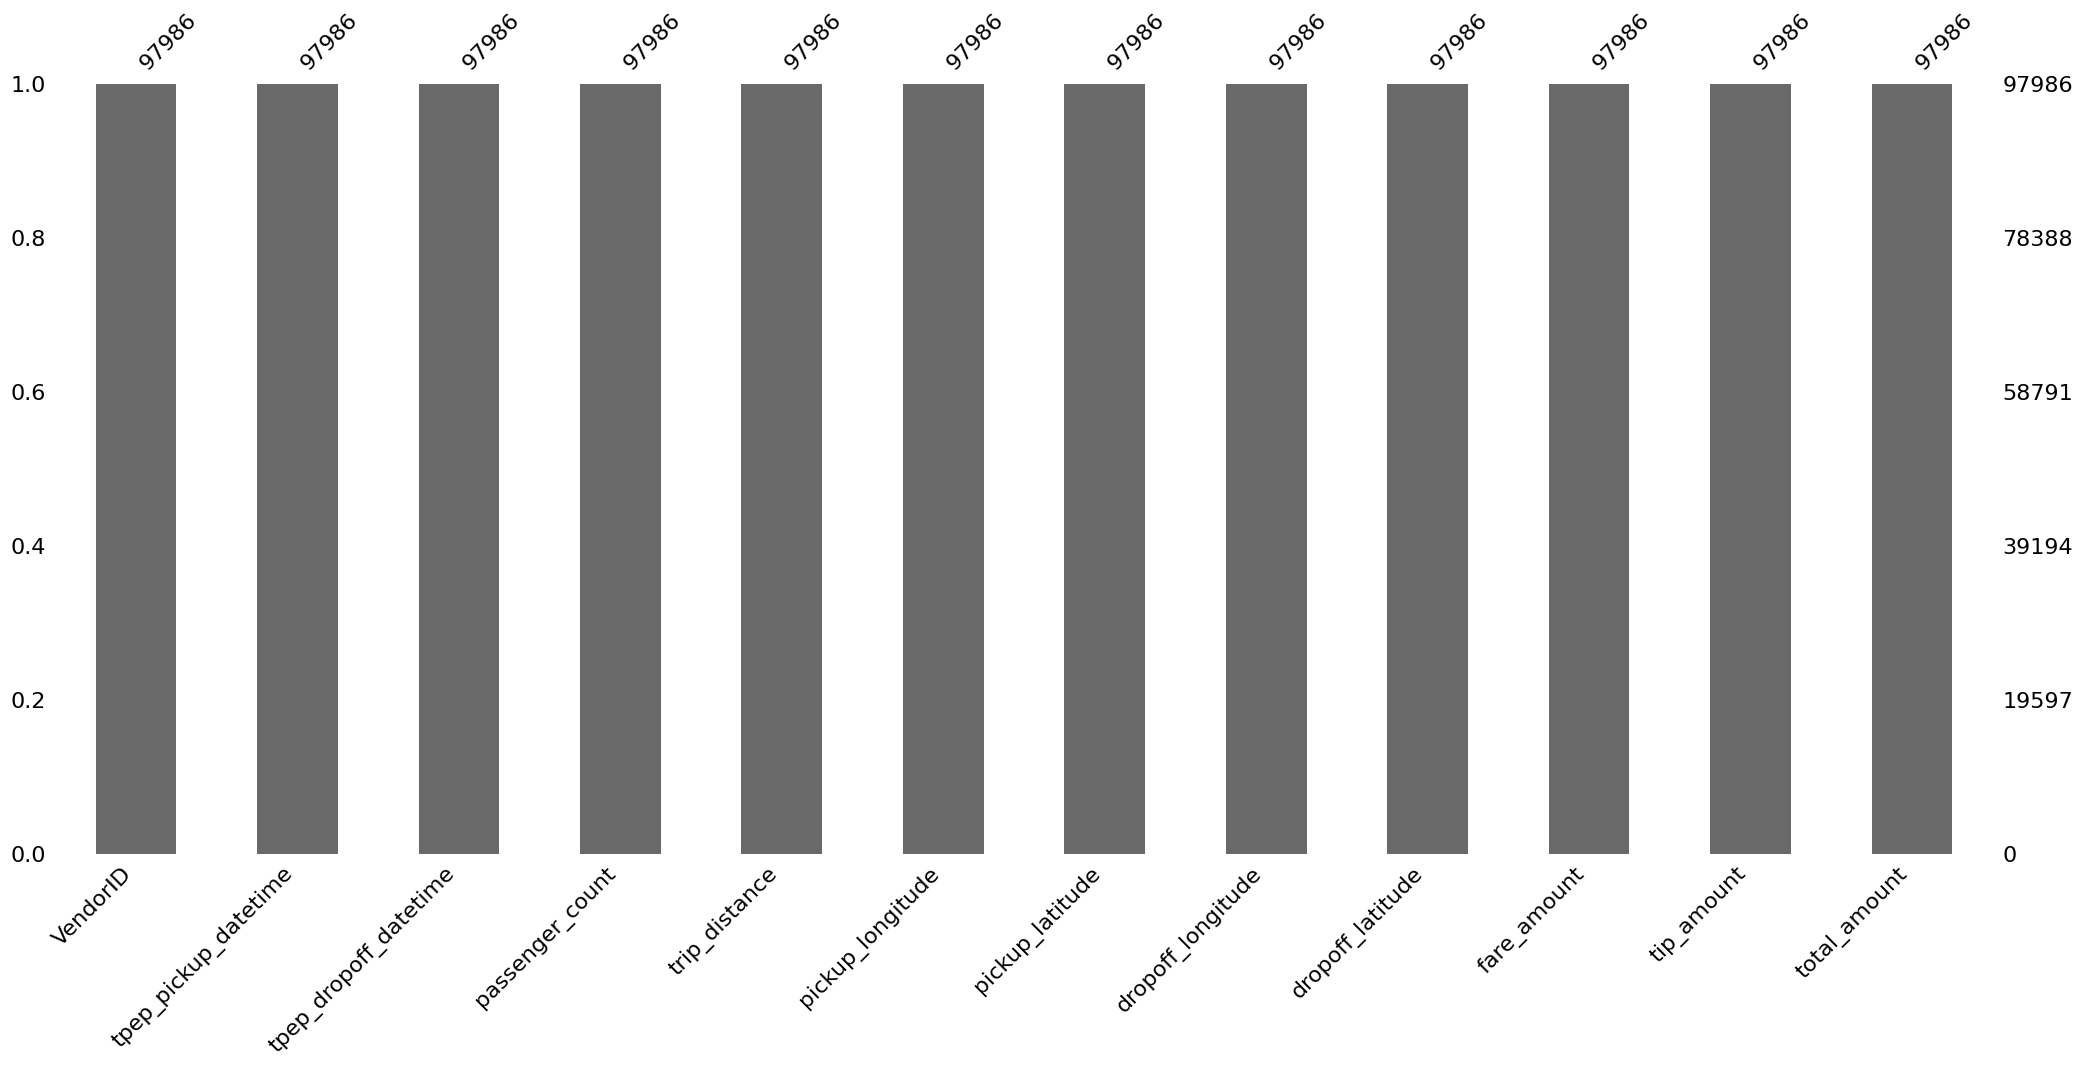

In [11]:
msno.bar(df2)
plt.show()

**Conclusion :** le dataset ne contient aucune valeur manquante

## 3. Nettoyage et préparation des données

In [12]:
df2['pickup'] = pd.to_datetime(df2['tpep_pickup_datetime']).dt.tz_localize(None)
df2['dropoff'] = pd.to_datetime(df2['tpep_dropoff_datetime']).dt.tz_localize(None)
print(df2['pickup'].min(), "->", df2['pickup'].max())

2015-01-15 00:01:32 -> 2015-01-15 23:59:59


In [13]:
df2['duration_min'] = (df2['dropoff'] - df2['pickup']).dt.total_seconds() / 60
df2['hour'] = df2['pickup'].dt.hour
df2['day_name'] = df2['pickup'].dt.day_name()
df2[['pickup', 'dropoff', 'duration_min', 'hour', 'day_name']].head()

,pickup,dropoff,duration_min,hour,day_name
0,2015-01-15 19:05:39,2015-01-15 19:23:42,18.050000,19,Thursday
1,2015-01-15 19:05:39,2015-01-15 19:32:00,26.350000,19,Thursday
2,2015-01-15 19:05:40,2015-01-15 19:21:00,15.333333,19,Thursday
3,2015-01-15 19:05:40,2015-01-15 19:28:18,22.633333,19,Thursday
4,2015-01-15 19:05:41,2015-01-15 19:20:36,14.916667,19,Thursday


In [15]:
n_before = len(df2)

# Zone approximative de New York
in_nyc = (df2['pickup_longitude'].between(-74.3, -73.7) &
          df2['pickup_latitude'].between(40.5, 41.0) &
          df2['dropoff_longitude'].between(-74.3, -73.7) &
          df2['dropoff_latitude'].between(40.5, 41.0))

valid = ((df2['duration_min'] > 0) & (df2['duration_min'] <= 180) &
         (df2['trip_distance'] > 0) & (df2['trip_distance'] <= 50) &
         (df2['passenger_count'] > 0) &
         (df2['fare_amount'] > 0) &
         in_nyc)

df_clean = df2[valid].copy()

# On retire aussi les vitesses impossibles (> 100 mph)
df_clean['speed_mph'] = df_clean['trip_distance'] / (df_clean['duration_min'] / 60)
df_clean = df_clean[df_clean['speed_mph'] <= 100]

print(f"Avant : {n_before} | Après : {len(df_clean)} | Supprimés : {n_before - len(df_clean)}")

Avant : 97986 | Après : 97306 | Supprimés : 680


### Critères de nettoyage
- **Durée** : entre 0 et 180 min (une durée nulle ou de plus de 3 h est une erreur).
- **Distance** : entre 0 et 50 miles.
- **Passagers** : au moins 1.
- **Tarif** : `fare_amount` > 0.
- **Localisation** : coordonnées GPS situées dans la zone de New York.
- **Vitesse** : au plus 100 mph (au-delà, le trajet est physiquement impossible).

Les colonnes `hour` et `day_name` ont été extraites de la date de départ.

## 4. Visualisations statistiques
### 4.1 Distribution des distances de trajet

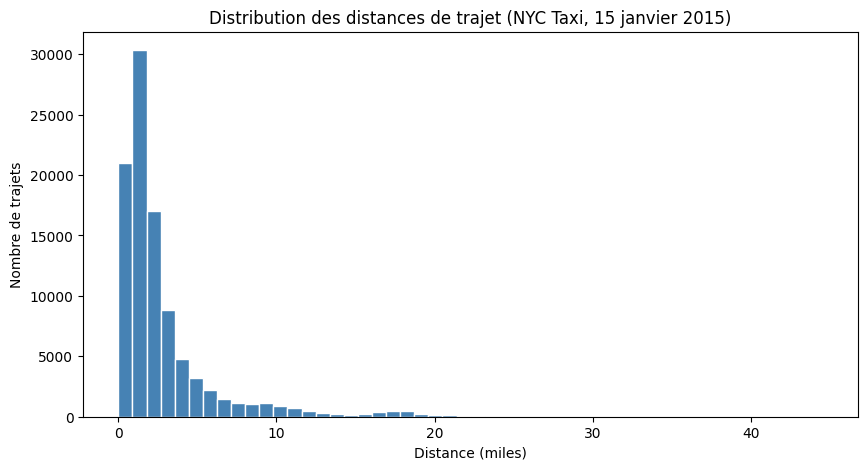

In [16]:
plt.figure(figsize=(10, 5))
plt.hist(df_clean['trip_distance'], bins=50, color='steelblue', edgecolor='white')
plt.title("Distribution des distances de trajet (NYC Taxi, 15 janvier 2015)")
plt.xlabel("Distance (miles)")
plt.ylabel("Nombre de trajets")
plt.show()

In [17]:
df_clean['trip_distance'].describe()

,trip_distance
count,97306.000000
mean,2.845181
std,3.401437
min,0.010000
25%,1.000000
50%,1.690000
75%,3.080000
max,44.550000


**Interprétation :** la plupart des trajets sont courts. La médiane est de 1,69 mile et 75 % des trajets font moins de 3,08 miles. Quelques trajets très longs (jusqu'à 44,55 miles) font monter la moyenne à 2,85 miles.

### 4.2 Nombre de trajets par heure de la journée

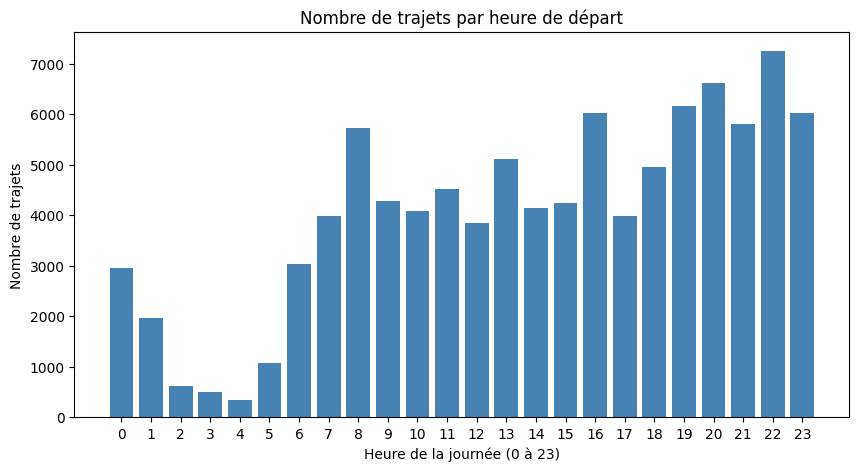

In [18]:
trips_per_hour = df_clean['hour'].value_counts().sort_index()

plt.figure(figsize=(10, 5))
plt.bar(trips_per_hour.index, trips_per_hour.values, color='steelblue')
plt.title("Nombre de trajets par heure de départ")
plt.xlabel("Heure de la journée (0 à 23)")
plt.ylabel("Nombre de trajets")
plt.xticks(range(0, 24))
plt.show()

In [19]:
trips_per_hour.sort_values(ascending=False).head(3)

,count
hour,
22,7263
20,6623
19,6158


 la demande est la plus forte en soirée, avec des pics à 19 h, 20 h et 22 h

## 5. Visualisations dynamiques
### 5.1 Carte interactive des points de départ (échantillon de 5 000 trajets)

In [21]:
sample = df_clean.sample(5000, random_state=42)

fig = px.scatter_map(
    sample,
    lat='pickup_latitude',
    lon='pickup_longitude',
    hover_data=['trip_distance', 'fare_amount', 'hour'],
    zoom=10,
    opacity=0.5,
    map_style='carto-positron',
    title="Points de départ des taxis (5 000 trajets)"
)
fig.show()

la grande majorité des départs se concentrent à Manhattan, surtout dans le centre (Midtown). On voit aussi deux petits groupes isolés, à l'est de la ville, qui correspondent aux aéroports JFK et LaGuardia. Le taxi est donc utilisé surtout au cœur de la ville, avec les aéroports comme points de départ secondaires.

### 5.2 Durée du trajet en fonction de la distance

In [22]:
fig = px.scatter(
    sample,
    x='trip_distance',
    y='duration_min',
    hover_data=['fare_amount', 'hour', 'passenger_count'],
    opacity=0.4,
    title="Durée du trajet en fonction de la distance (5 000 trajets)",
    labels={'trip_distance': 'Distance (miles)', 'duration_min': 'Durée (minutes)'}
)
fig.show()

In [23]:
df_clean[['trip_distance', 'duration_min']].corr()

,trip_distance,duration_min
trip_distance,1.000000,0.804245
duration_min,0.804245,1.000000


la durée augmente avec la distance (corrélation de 0,80). Mais pour une même distance, la durée varie beaucoup, surtout sur les trajets longs : par exemple, certains trajets de 8 miles durent plus de 70 minutes alors que d'autres en font 20. Ces trajets anormalement lents correspondent probablement à des embouteillages.

### 5.3 Indicateurs clés (KPI)

In [24]:
kpi = {
    "Nombre de trajets": len(df_clean),
    "Distance moyenne (miles)": round(df_clean['trip_distance'].mean(), 2),
    "Durée moyenne (min)": round(df_clean['duration_min'].mean(), 1),
    "Vitesse moyenne (mph)": round(df_clean['speed_mph'].mean(), 1),
    "Tarif moyen ($)": round(df_clean['fare_amount'].mean(), 2),
    "Pourboire moyen ($)": round(df_clean['tip_amount'].mean(), 2),
    "Heure de pointe": f"{trips_per_hour.idxmax()} h",
}

kpi_df = pd.DataFrame(kpi.items(), columns=['KPI', 'Valeur'])
kpi_df

,KPI,Valeur
0,Nombre de trajets,97306
1,Distance moyenne (miles),2.85
2,Durée moyenne (min),13.3
3,Vitesse moyenne (mph),11.9
4,Tarif moyen ($),12.28
5,Pourboire moyen ($),1.7
6,Heure de pointe,22 h


le taxi new-yorkais est un transport de courte distance : un trajet moyen fait 2,85 miles et dure 13 minutes, pour un tarif moyen de 12,28 dollars. La vitesse moyenne n'est que de 11,9 mph, ce qui montre que la circulation est lente en ville. Le pourboire moyen est de 1,70 dollar, soit environ 14 % du tarif. L'heure de pointe est 22 h.

## 6. Storytelling : ce que racontent les taxis de New York

**Le contexte.** Ce jeu de données contient 97 306 trajets valides (après nettoyage) effectués le jeudi 15 janvier 2015.

**Dans le temps.** La demande est la plus forte en soirée, avec des pics à 19 h, 20 h et 22 h : retour du travail puis sorties du soir. La demande est la plus faible la nuit.

**Dans l'espace.** Les départs sont concentrés à Manhattan, surtout dans le centre. Les aéroports JFK et LaGuardia forment deux petits points chauds isolés.

**Les trajets.** Le taxi sert surtout à de courts déplacements : la médiane est de 1,69 mile et 75 % des trajets font moins de 3,08 miles. Un trajet moyen dure 13 minutes et coûte 12,28 dollars.

**La circulation.** La durée augmente avec la distance (corrélation de 0,80), mais elle varie beaucoup pour une même distance. La vitesse moyenne n'est que de 11,9 mph : la congestion ralentit les taxis.

### Recommandations (vision BI)
- Renforcer le nombre de taxis disponibles en soirée (19 h à 22 h), quand la demande est la plus forte.
- Concentrer l'offre à Manhattan, et prévoir une présence aux aéroports pour les courses longues et plus rentables.
- Tenir compte de la congestion dans la planification : un trajet de même distance peut durer très différemment selon l'heure.

### Limites
Les données couvrent une seule journée : les conclusions décrivent un jeudi de janvier et ne peuvent pas être généralisées à toute l'année.